<a href="https://colab.research.google.com/github/rm237-rice/ELEC-576/blob/main/assignment_2_part_1_trainCifarStarterCode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# -*- coding: utf-8 -*-
"""Assignment_2_Part_1_Cifar10_vp1.ipynb

Purpose: Implement image classification nn the cifar10
dataset using a pytorch implementation of a CNN architecture (LeNet5)

Pseudocode:
1) Set Pytorch metada
- seed
- tensorboard output (logging)
- whether to transfer to gpu (cuda)

2) Import the data
- download the data
- create the pytorch datasets
    scaling
- create pytorch dataloaders
    transforms
    batch size

3) Define the model architecture, loss and optimizer

4) Define Test and Training loop
    - Train:
        a. get next batch
        b. forward pass through model
        c. calculate loss
        d. backward pass from loss (calculates the gradient for each parameter)
        e. optimizer: performs weight updates
        f. Calculate accuracy, other stats
    - Test:
        a. Calculate loss, accuracy, other stats

5) Perform Training over multiple epochs:
    Each epoch:
    - call train loop
    - call test loop
"""

'Assignment_2_Part_1_Cifar10_vp1.ipynb\n\nPurpose: Implement image classification nn the cifar10\ndataset using a pytorch implementation of a CNN architecture (LeNet5)\n\nPseudocode:\n1) Set Pytorch metada\n- seed\n- tensorboard output (logging)\n- whether to transfer to gpu (cuda)\n\n2) Import the data\n- download the data\n- create the pytorch datasets\n    scaling\n- create pytorch dataloaders\n    transforms\n    batch size\n\n3) Define the model architecture, loss and optimizer\n\n4) Define Test and Training loop\n    - Train:\n        a. get next batch\n        b. forward pass through model\n        c. calculate loss\n        d. backward pass from loss (calculates the gradient for each parameter)\n        e. optimizer: performs weight updates\n        f. Calculate accuracy, other stats\n    - Test:\n        a. Calculate loss, accuracy, other stats\n\n5) Perform Training over multiple epochs:\n    Each epoch:\n    - call train loop\n    - call test loop\n'

Step 1: Pytorch and Training Metadata



In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms.v2 as transformsV2
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
import os
from pathlib import Path

#hyperparameters
batch_size = 128
epochs = 10
lr = 0.001
try_cuda = True
seed = 1000

# Architecture
num_classes = 10

#otherum
logging_interval = 10 # how many batches to wait before logging
logging_dir = None
grayscale = True

# 1) setting up the logging

datetime_str = datetime.now().strftime('%b%d_%H-%M-%S')

if logging_dir is None:
    runs_dir = Path("./") / Path(f"runs/")
    runs_dir.mkdir(exist_ok = True)

    logging_dir = runs_dir / Path(f"{datetime_str}")

    logging_dir.mkdir(exist_ok = True)
    logging_dir = str(logging_dir.absolute())

writer = SummaryWriter(log_dir=logging_dir)

#deciding whether to send to the cpu or not if available
if torch.cuda.is_available() and try_cuda:
    cuda = True
    torch.cuda.manual_seed(seed)
else:
    cuda = False
    torch.manual_seed(seed)

Step 2: Data Setup

In [10]:
# # downloading the cifar10 dataset
# from google.colab import files
# uploaded = files.upload()

In [24]:
# extracting the CIFAR10-1 zip file
import zipfile
import os

zip_path = 'CIFAR10-1.zip'
extract_path = './cifar10_extracted'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files structure:")
print(os.listdir(extract_path))

Extracted files structure:
['CIFAR10']


In [28]:
import torch.nn.functional as F

num_classes = 10

# grayscale image transform
transform = transformsV2.Compose([
    transformsV2.Grayscale(num_output_channels=1),
    transformsV2.ToImage(),
    transformsV2.ToDtype(torch.float32, scale=True)
])

# target transform to convert integer labels to one-hot encoded tensors
target_transform = transformsV2.Lambda(
    lambda y: F.one_hot(torch.tensor(y), num_classes=num_classes).float()
)

In [29]:
# Load dataset applying 'transform' on images and 'target_transform' on the labels
train_dataset = datasets.ImageFolder(
    root='./cifar10_extracted/CIFAR10/Train',
    transform=transform,
    target_transform=target_transform
)

test_dataset = datasets.ImageFolder(
    root='./cifar10_extracted/CIFAR10/Test',
    transform=transform,
    target_transform=target_transform
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

In [30]:
def check_data_loader_dim(loader):
    # Checking the dataset
    for images, labels in loader:
        print('Image batch dimensions:', images.shape)
        print('Image label dimensions:', labels.shape)
        break

check_data_loader_dim(train_loader)
check_data_loader_dim(test_loader)

Image batch dimensions: torch.Size([128, 1, 28, 28])
Image label dimensions: torch.Size([128, 10])
Image batch dimensions: torch.Size([128, 1, 28, 28])
Image label dimensions: torch.Size([128, 10])


Feature batch shape: torch.Size([128, 1, 28, 28])
Labels batch shape: torch.Size([128, 10])


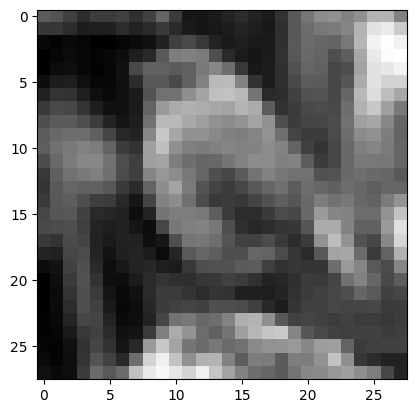

Label: tensor([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])


In [32]:
import matplotlib.pyplot as plt

# Display image and label.
train_features, train_labels = next(iter(train_loader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

Step 3: Creating the Model

In [ ]:
layer_1_n_filters = [insert-code]
layer_2_n_filters = [insert-code]
fc_1_n_nodes = [insert-code]
kernel_size = 5
verbose = False

# calculating the side length of the final activation maps
final_length = [insert-code: calculate the dimension of the output of the \
            CNN stage before the MLP layers given the previous 2 convolutional layers \
                with your padding setting, kernel size and maxpooling
            ]

if verbose:
    print(f"final_length = {final_length}")


class LeNet5(nn.Module):

    def __init__(self, num_classes, grayscale=False):
        super(LeNet5, self).__init__()

        self.grayscale = grayscale
        self.num_classes = num_classes

        if self.grayscale:
            in_channels = 1
        else:
            in_channels = 3

        self.features = nn.Sequential(

            [insert-code]
        )

        self.classifier = nn.Sequential(
            nn.Linear(final_length*final_length*layer_2_n_filters*in_channels, fc_1_n_nodes),
            nn.Tanh(),
            nn.Linear(fc_1_n_nodes, num_classes)
        )


    def forward(self, x):
        x = [insert-code: send input through convolutional layers]
        x = [insert-code: send input through MLP layers]
        logits = self.classifier(x)
        probas = F.softmax(logits, dim=1)
        return logits, probas

model = [insert-code]

if cuda:
    model.cuda()

optimizer = [insert-code: USE AN ADAM OPTIMIZER]

Step 4: Train/Test Loop

In [ ]:
# Defining the test and trainig loops

def train(epoch):
    model.train()

    criterion = [insert-code]  # The choice of criterion depends on the output of the last layer of your network
    for batch_idx, (data, target) in enumerate(train_loader):
        [insert-code: move data to GPU]

        optimizer.zero_grad()
        logits,probas = model(data) # forward

        loss = [insert-code]
        loss.backward()
        optimizer.step()

        # log metrics
        [insert-code: finish training loop and logging metrics]

    #
    [insert-code: Log model parameters to TensorBoard at every epoch]

def test(epoch):
    model.eval()
    test_loss = 0
    correct = 0
    criterion = [insert-code]  # The choice of criterion depends on the output of the last layer of your network

    with torch.no_grad():
        for data, target in test_loader:
            [insert-code: move data to GPU]

            logits,probas  = model(data)

            # Calculate the predicted label (highest probability)
            # Calculate the number of correct prediction and accuracy

            [insert-code: finish testing loop and logging metrics]


[insert-code: running test and training over epoch]

writer.close()

In [ ]:
# Commented out IPython magic to ensure Python compatibility.
"""
#https://stackoverflow.com/questions/55970686/tensorboard-not-found-as-magic-function-in-jupyter

#seems to be working in firefox when not working in Google Chrome when running in Colab
#https://stackoverflow.com/questions/64218755/getting-error-403-in-google-colab-with-tensorboard-with-firefox


# %load_ext tensorboard
# %tensorboard --logdir [dir]

"""